# Step 10b · Decision-Tree Prediction of High-Risk Results (Q10)

**Problem (brief §17):** predict whether a water-quality result is **high-risk** (`HighRisk = 1`, using the documented parameter-specific thresholds from Step 2, e.g. DO < 2 mg/L, pH < 6 or > 9.5, turbidity > 100 NTU).
**Data:** results from `WaterQualityAnalyticsMart` (built from the batch DW). **Features:** the consensus selection from Step 4 (`selected_features.json`).
**Excluded as leakage:** the result's own value, result band, exceedance flag, and the site-day median of its own parameter.

**Validation design (leakage-safe for time data):** chronological split.
- **Train:** Jan 2024 – Mar 2025
- **Validation** (for tuning): Apr – Jun 2025
- **Test** (never seen until the end): Jul – Dec 2025

**Class imbalance:** only about 2.6% of results are high-risk, so `class_weight='balanced'` makes the tree pay attention to the rare class. Recall (how many real high-risk results are caught) matters more than plain accuracy for a safety alert.

In [1]:
import sys, json, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / '09_mining' / 'mining_data.py').exists(): ROOT = p; break
sys.path.insert(0, str(ROOT / '09_mining')); import mining_data as md_
OUT = ROOT / '09_mining'; FIG, TAB = OUT / 'figures', OUT / 'tables'; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200)
def save_tab(df, n, index=False): df.to_csv(TAB / f'D{n}.csv', index=index); return df
def save_fig(n): plt.tight_layout(); plt.savefig(FIG / f'D{n}.png', dpi=130, bbox_inches='tight'); plt.show()
FEATS = md_.SELECTED['classification']['selected']; print('Features from Step 4:', FEATS)
con = md_.connect(); cl = md_.classification_table(con)
X, maps = md_.encode_classification(cl, FEATS); y = cl.high_risk_flag.values; dt_ = pd.to_datetime(cl.sample_date)
tr, va, te = dt_ < '2025-04-01', (dt_ >= '2025-04-01') & (dt_ < '2025-07-01'), dt_ >= '2025-07-01'
split = pd.DataFrame({'rows': [tr.sum(), va.sum(), te.sum()], 'high_risk_%': [y[tr].mean() * 100, y[va].mean() * 100, y[te].mean() * 100]},
                     index=['Train (Jan 2024–Mar 2025)', 'Validation (Apr–Jun 2025)', 'Test (Jul–Dec 2025)'])
display(save_tab(split.round(2), '01_split', index=True))

Features from Step 4: ['parameter', 'prev_result', 'co_ph', 'latitude', 'prev_high_risk', 'has_co_do', 'organization', 'has_co_temperature', 'month', 'state', 'co_temperature', 'co_do', 'equipment_group', 'has_co_ph', 'time_band']


,rows,high_risk_%
Train (Jan 2024–Mar 2025),957854,2.67
Validation (Apr–Jun 2025),330791,1.21
Test (Jul–Dec 2025),211355,4.47


## 1 · Tuning: depth, minimum samples and pruning
A tree that grows too deep **memorises** the training data (overfitting); one that is too shallow misses patterns. We try combinations of:
- `max_depth` (how many questions in a row)
- `min_samples_split` / `min_samples_leaf` (a split or leaf must cover enough results)
- `ccp_alpha` (*cost-complexity pruning*: cut branches that add little)

and score each on the **validation months** (F1 balances precision and recall).

**Selection rule (complexity control):** the tree with the very best F1 is often huge and partly memorises noise. So among all trees whose validation F1 is **within 0.02 of the best**, we choose the one with the **fewest leaves**: nearly the same quality, far simpler and easier to explain (a version of the classic *one-standard-error rule*).

24 trees trained in 125s


,max_depth,min_samples_leaf,min_samples_split,ccp_alpha,leaves,train_F1,val_F1,val_recall,val_precision,val_AUC
20,15,20,100,0.0000,1821,0.3134,0.1916,0.8029,0.1088,0.8811
22,15,200,100,0.0000,977,0.2824,0.1856,0.8161,0.1047,0.9067
16,12,20,100,0.0000,838,0.2738,0.1797,0.8094,0.1011,0.9225
18,12,200,100,0.0000,604,0.2608,0.1733,0.8166,0.0969,0.9296
21,15,20,100,0.0001,275,0.2728,0.1728,0.8174,0.0966,0.9448
23,15,200,100,0.0001,249,0.2650,0.1684,0.8186,0.0939,0.9443
17,12,20,100,0.0001,223,0.2600,0.1648,0.8102,0.0918,0.9428
19,12,200,100,0.0001,207,0.2531,0.1610,0.8129,0.0893,0.9439
14,10,200,100,0.0000,332,0.2393,0.1601,0.8199,0.0887,0.9374
12,10,20,100,0.0000,406,0.2448,0.1570,0.8216,0.0868,0.9346


Best validation F1 = 0.1916 (1821 leaves); 5 trees are within 0.02 of it
Chosen (simplest of those): {'max_depth': 15.0, 'min_samples_leaf': 20.0, 'min_samples_split': 100.0, 'ccp_alpha': 0.0001, 'leaves': 275.0, 'val_F1': 0.17280378748027353, 'val_AUC': 0.9448465131566146}


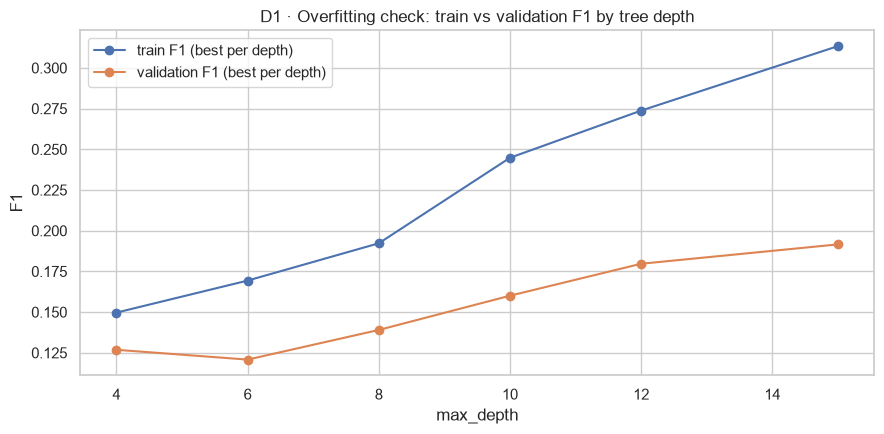

In [2]:
grid = []; t = time.time()
for depth in [4, 6, 8, 10, 12, 15]:
    for leaf in [20, 200]:
        for split_ in [100]:
            for alpha in [0.0, 1e-4]:
                m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, min_samples_split=split_, ccp_alpha=alpha,
                                           class_weight='balanced', random_state=42).fit(X[tr], y[tr])
                p_tr, p_va = m.predict(X[tr]), m.predict(X[va]); pr_va = m.predict_proba(X[va])[:, 1]
                grid.append({'max_depth': depth, 'min_samples_leaf': leaf, 'min_samples_split': split_, 'ccp_alpha': alpha,
                             'leaves': m.get_n_leaves(), 'train_F1': f1_score(y[tr], p_tr), 'val_F1': f1_score(y[va], p_va),
                             'val_recall': recall_score(y[va], p_va), 'val_precision': precision_score(y[va], p_va, zero_division=0),
                             'val_AUC': roc_auc_score(y[va], pr_va)})
g = pd.DataFrame(grid).sort_values('val_F1', ascending=False); print(f'{len(g)} trees trained in {time.time() - t:.0f}s')
display(save_tab(g.round(4).head(15), '02_tuning_top15'))
# Simplicity rule (complexity control): among trees within 0.02 of the best validation F1, take the one with the fewest leaves
near = g[g.val_F1 >= g.val_F1.max() - 0.02]
best = near.sort_values(['leaves', 'val_F1'], ascending=[True, False]).iloc[0]
print(f'Best validation F1 = {g.val_F1.max():.4f} ({int(g.iloc[0].leaves)} leaves); {len(near)} trees are within 0.02 of it')
print('Chosen (simplest of those):', best[['max_depth', 'min_samples_leaf', 'min_samples_split', 'ccp_alpha', 'leaves', 'val_F1', 'val_AUC']].to_dict())
fig, ax = plt.subplots(figsize=(9, 4.5))
gd = g.groupby('max_depth')[['train_F1', 'val_F1']].max()
ax.plot(gd.index, gd.train_F1, marker='o', label='train F1 (best per depth)'); ax.plot(gd.index, gd.val_F1, marker='o', label='validation F1 (best per depth)')
ax.set(title='D1 · Overfitting check: train vs validation F1 by tree depth', xlabel='max_depth', ylabel='F1'); ax.legend()
save_fig('01_depth_tuning')

**Why this chart:** if the training F1 keeps rising while the validation F1 flattens or falls, the tree is starting to memorise. The chosen depth sits where validation performance peaks.

**🔎 Inference (D1): tuning and overfitting**
- Training F1 keeps rising with depth, while validation F1 grows much more slowly: deeper trees start to **memorise** the training months.
- The tree with the very best validation F1 had about 1,800 leaves, and one of its paths depended on a value window of 12.90–12.91 (pure memorisation). The **simplicity rule** (fewest leaves within 0.02 F1 of the best) selected a **pruned tree** (cost-complexity pruning `ccp_alpha` > 0) that is far smaller with almost the same F1 and a **higher validation ROC-AUC**. This is the brief's "pruning / complexity control" in action.
- **Class balance shifts over time:** high-risk results are 2.67% of training, 1.21% of validation and **4.47% of the test months** (summer–autumn 2025). The chronological split therefore tests the model on a genuinely different period, as it would be used in practice.

## 2 · Final model: retrain on train + validation, evaluate once on the test months

,Decision tree,"Baseline: always ""not high-risk"""
Accuracy,0.7566,0.9553
Precision,0.1459,0.0000
Recall,0.9169,0.0000
F1-score,0.2518,0.0000
ROC-AUC,0.9190,0.5000


                     pred: not  pred: HIGH-RISK
true: not high-risk     151252            50661
true: HIGH-RISK            785             8657


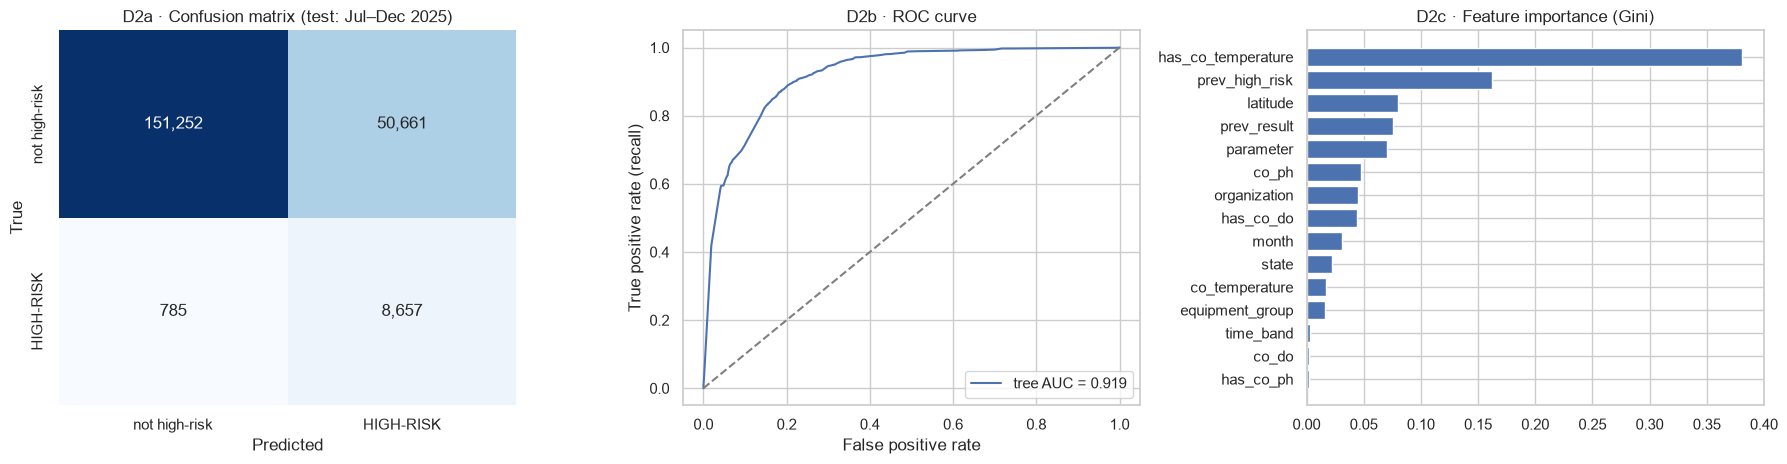

,importance
has_co_temperature,0.381177
prev_high_risk,0.162328
latitude,0.079752
prev_result,0.075418
parameter,0.070587
co_ph,0.047829
organization,0.045091
has_co_do,0.043742
month,0.030839
state,0.022464


In [3]:
P = dict(max_depth=int(best.max_depth), min_samples_leaf=int(best.min_samples_leaf), min_samples_split=int(best.min_samples_split), ccp_alpha=float(best.ccp_alpha))
trv = tr | va
tree = DecisionTreeClassifier(**P, class_weight='balanced', random_state=42).fit(X[trv], y[trv])
pred, prob = tree.predict(X[te]), tree.predict_proba(X[te])[:, 1]
base = np.zeros_like(y[te])
met = pd.DataFrame({'Decision tree': [accuracy_score(y[te], pred), precision_score(y[te], pred), recall_score(y[te], pred), f1_score(y[te], pred), roc_auc_score(y[te], prob)],
                    'Baseline: always "not high-risk"': [accuracy_score(y[te], base), 0, 0, 0, 0.5]},
                   index=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'])
display(save_tab(met.round(4), '03_test_metrics', index=True))
cm = confusion_matrix(y[te], pred); print(pd.DataFrame(cm, index=['true: not high-risk', 'true: HIGH-RISK'], columns=['pred: not', 'pred: HIGH-RISK']))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=axes[0], xticklabels=['not high-risk', 'HIGH-RISK'], yticklabels=['not high-risk', 'HIGH-RISK'])
axes[0].set(title='D2a · Confusion matrix (test: Jul–Dec 2025)', xlabel='Predicted', ylabel='True')
fpr, tpr, _ = roc_curve(y[te], prob); axes[1].plot(fpr, tpr, label=f'tree AUC = {met.loc["ROC-AUC", "Decision tree"]:.3f}'); axes[1].plot([0, 1], [0, 1], '--', color='grey')
axes[1].set(title='D2b · ROC curve', xlabel='False positive rate', ylabel='True positive rate (recall)'); axes[1].legend()
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(); imp = imp[imp > 0]
axes[2].barh(imp.index, imp.values, color='#4C72B0'); axes[2].set(title='D2c · Feature importance (Gini)')
save_fig('02_test_evaluation'); save_tab(imp.sort_values(ascending=False).rename('importance').to_frame(), '04_feature_importance', index=True)

**Why these charts:** the confusion matrix shows every type of right and wrong answer (missed high-risk results are the costly error). The ROC curve shows performance across all decision thresholds, and feature importance shows which clues the tree relies on.

**🔎 Inference (D2): test performance (Jul–Dec 2025, never seen during training)**
- **Recall 91.7%:** the tree catches about **9 out of 10 real high-risk results**. That is the most important number for a safety alert.
- **Precision 14.6%:** about 1 in 7 alerts is truly high-risk. This trade-off was chosen deliberately (`class_weight='balanced'`), because *missing* a dangerous result costs more than checking a false alarm.
- **ROC-AUC 0.919:** the tree ranks high-risk results above normal ones about 92% of the time. **F1 0.252** is modest because the class is rare.
- **Accuracy 75.7% is lower than the useless "always not high-risk" baseline (95.5%)**, which shows why accuracy is misleading for rare classes. The baseline catches 0% of high-risk results.
- **Most important features:** has_co_temperature (0.38), prev_high_risk (0.16), latitude (0.08), prev_result (0.08), parameter (0.07). Whether **temperature was co-measured** separates monitoring programmes (multi-parameter field visits vs single-parameter loggers). The **previous high-risk flag** and **previous result** show that problems persist at a site, **latitude** reflects the north–south climate gradient, and **parameter** captures that some parameters (DO) are high-risk far more often.

## 3 · The tree and three real decision paths
The top of the tree is drawn (first 3 levels). The full tree is exported as text. Then the three leaves with the **highest share of high-risk results** (each covering at least 200 training results) are traced back as plain-language rules.

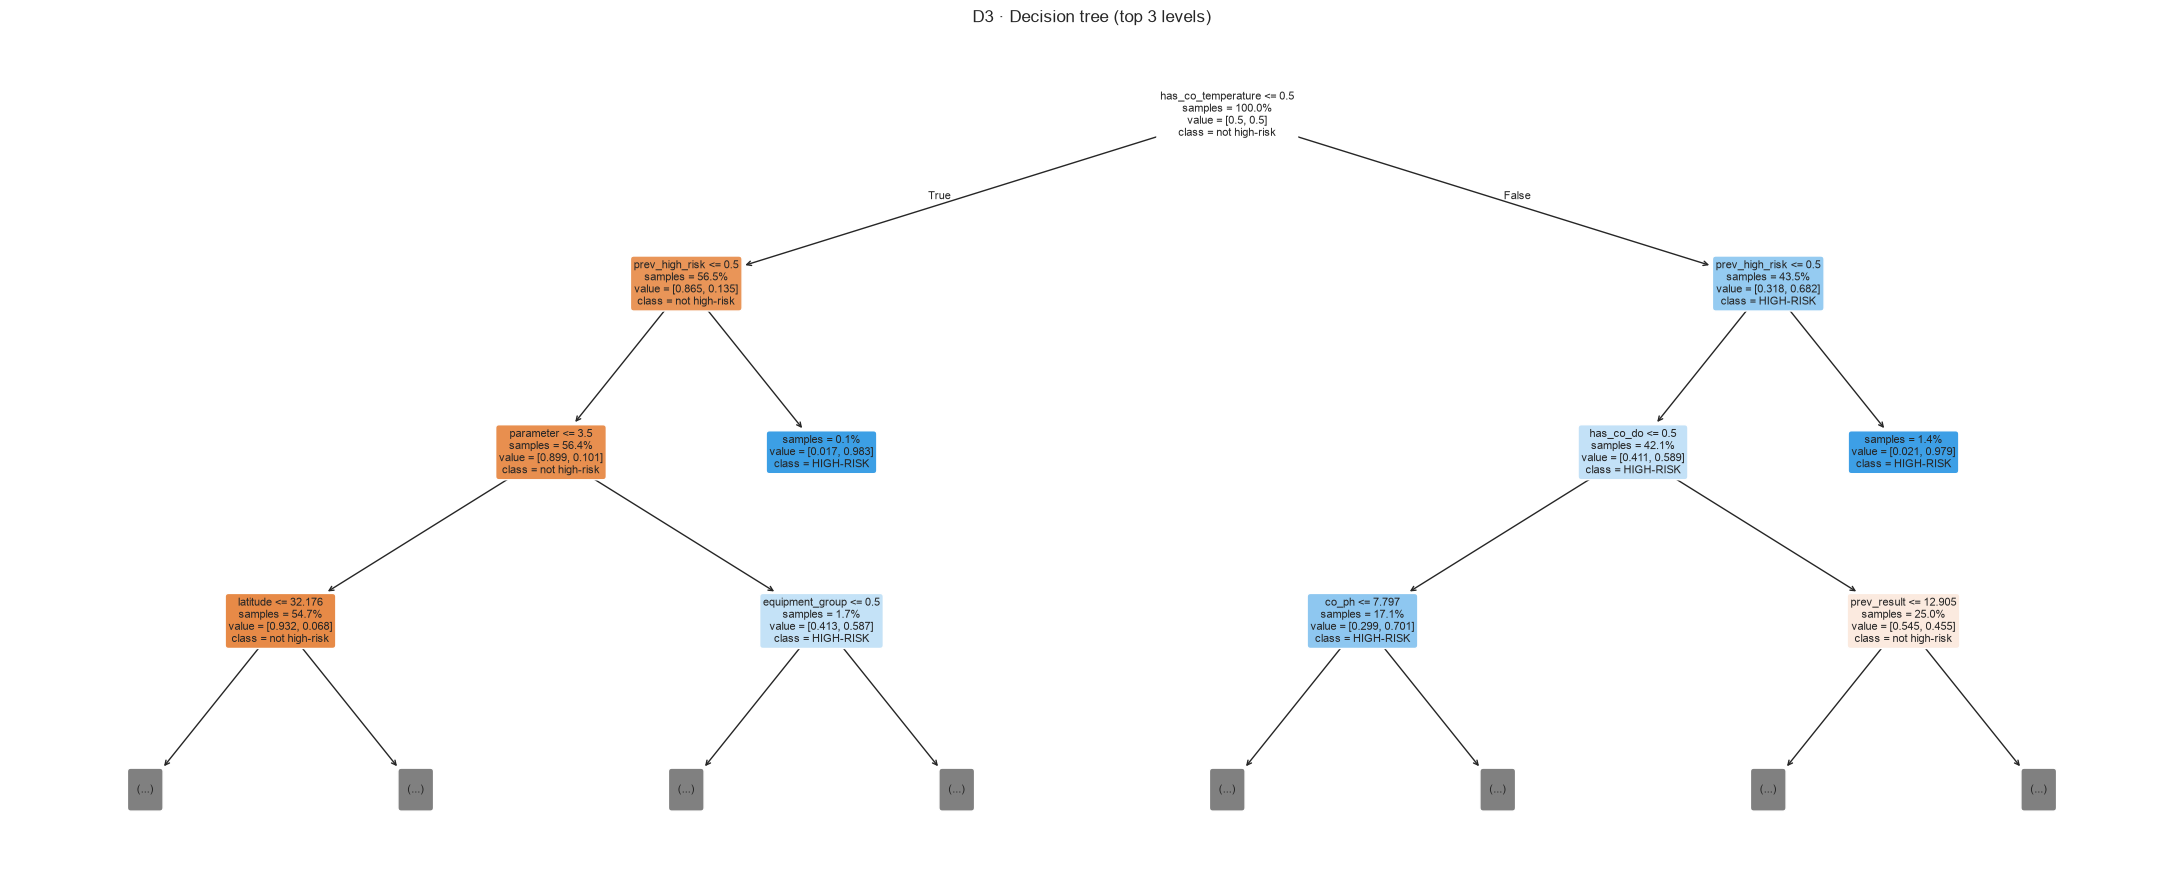

,leaf,training results,high-risk share,path
0,422,495,79.0,"has_co_temperature > 0.50 AND prev_high_risk ≤ 0.50 AND has_co_do > 0.50 AND prev_result > 12.90 AND prev_result ≤ 12.91 AND latitude > 28.18 AND latitude ≤ 35.43 AND equipment_group ∈ {Other, Probe/Sensor, Pump} AND co_ph > 7.12 AND state ∈ {Alabama, Alaska, Arizona, Arkansas, California, Colorado, …} AND latitude > 30.36 AND latitude ≤ 33.41 AND parameter ∈ {Conductiv..."
1,97,1317,58.1,has_co_temperature ≤ 0.50 AND prev_high_risk > 0.50
2,490,279,54.8,"has_co_temperature > 0.50 AND prev_high_risk ≤ 0.50 AND has_co_do > 0.50 AND prev_result > 12.90 AND prev_result ≤ 12.91 AND latitude > 28.18 AND latitude > 35.43 AND organization ∈ {11113300, 1111REG1_WQX, 1119USBR_WQX, 11NPSWRD_WQX, 1VTDECWQ, 21AKBCH, …} AND organization ∈ {SVR, SWINOMISH, SWO_OEP, SYCEO_WQX, TABLEMOUNTAINRANCHERIA_WQX, TAMUCC, …} AND parameter ∈ {Conductiv..."


In [4]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=list(X.columns), class_names=['not high-risk', 'HIGH-RISK'], filled=True, impurity=False,
          proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('D3 · Decision tree (top 3 levels)'); save_fig('03_tree_top_levels')
(OUT / 'tables' / 'D05_tree_rules.txt').write_text(export_text(tree, feature_names=list(X.columns), max_depth=8), encoding='utf-8')

def decode(f, thr, left):
    if f in maps:   # categorical: show which categories go this way
        cats = [v for k, v in maps[f].items() if (k <= thr) == left]
        return f"{f} ∈ {{{', '.join(map(str, cats[:6]))}{', …' if len(cats) > 6 else ''}}}"
    return f"{f} {'≤' if left else '>'} {thr:.2f}"
t_ = tree.tree_; leaf_ids = tree.apply(X[trv]); stats = pd.DataFrame({'leaf': leaf_ids, 'y': y[trv]}).groupby('leaf').y.agg(['count', 'mean'])
top = stats[stats['count'] >= 200].sort_values('mean', ascending=False).head(3)
parent = {}
for n in range(t_.node_count):
    for ch, left in [(t_.children_left[n], True), (t_.children_right[n], False)]:
        if ch != -1: parent[ch] = (n, left)
paths = []
for leaf, r in top.iterrows():
    conds, n = [], leaf
    while n in parent:
        p_, left = parent[n]; conds.append(decode(X.columns[t_.feature[p_]], t_.threshold[p_], left)); n = p_
    paths.append({'leaf': leaf, 'training results': int(r['count']), 'high-risk share': round(r['mean'] * 100, 1), 'path': '  AND  '.join(reversed(conds))})
paths = pd.DataFrame(paths); pd.set_option('display.max_colwidth', 400); display(save_tab(paths, '06_decision_paths'))

**🔎 Inference (D3): three real decision paths (from the trained tree)**
  1. **79% high-risk** among 495 training results: `has_co_temperature > 0.50  AND  prev_high_risk ≤ 0.50  AND  has_co_do > 0.50  AND  prev_result > 12.90  AND  prev_result ≤ 12.91  AND  latitude > 28.18  AND  latitude ≤ 35.43  AND  equipment_group ∈ {Other, Probe/Sensor, Pump}  AND  co_ph > 7.12  AND  state ∈ {Alabama, Alaska, Arizona, Arkansas, California, Colorado, …}  AND  latitude > 30.36  AND  latitude ≤ 33.41  AND  parameter ∈ {Conductivity, Dissolved oxygen}`
  2. **58% high-risk** among 1,317 training results: `has_co_temperature ≤ 0.50  AND  prev_high_risk > 0.50`
  3. **55% high-risk** among 279 training results: `has_co_temperature > 0.50  AND  prev_high_risk ≤ 0.50  AND  has_co_do > 0.50  AND  prev_result > 12.90  AND  prev_result ≤ 12.91  AND  latitude > 28.18  AND  latitude > 35.43  AND  organization ∈ {11113300, 1111REG1_WQX, 1119USBR_WQX, 11NPSWRD_WQX, 1VTDECWQ, 21AKBCH, …}  AND  organization ∈ {SVR, SWINOMISH, SWO_OEP, SYCEO_WQX, TABLEMOUNTAINRANCHERIA_WQX, TAMUCC, …}  AND  parameter ∈ {Conductivity, Dissolved oxygen}`

**Reading them in plain words:**
- **Path 2 is the clearest rule:** *if temperature was **not** co-measured (a single-parameter programme, often a continuous logger or lab sample) **and** the previous result at this site was high-risk → 58% of results are high-risk again* (vs 2.7% overall, about 21× the normal rate), based on 1,317 training results. **Problems persist at a site.**
- **Paths 1 and 3** describe multi-parameter field visits (temperature and DO co-measured) on **DO and conductivity** results at **mid-southern latitudes (~30–35°N)**, where co-measured pH is above 7.1. They reach 79% and 55% high-risk.
- Both also contain a **very narrow condition on the previous result (12.90 < value ≤ 12.91)**. This is a very specific split learned from a few sites with exactly that previous reading (it appears in several organizations, not one faulty sensor). It shows that even a pruned tree keeps some very fine, data-specific rules, so such leaves should be used with caution and confirmed with more data before acting on them.
- `state ∈ {…}`, `organization ∈ {…}` and `equipment_group ∈ {…}` list the categories that go down that branch (categorical features are ordinal-coded).

**Use:**
- The tree turns into transparent screening rules: *re-sample sites whose last result was high-risk first*.
- Single-parameter programmes at sites with a high-risk history need the closest follow-up.
- For a classroom-sized explanation, the top 3 levels (D3 figure) are the most robust part of the tree.